In [1]:
import os
from uuid import uuid4

from dotenv import load_dotenv
from IPython.display import Image, display
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.graph.state import CompiledStateGraph
from langgraph.prebuilt import ToolNode
from tavily import TavilyClient

In [2]:
load_dotenv()

model = "gpt-5.6-sol"

llm = ChatOpenAI(
    model=model,
    temperature=0.0,
    max_completion_tokens=500,
    timeout=50,
    reasoning_effort="low",
    max_retries=2,
)

In [3]:
@tool
def web_search(question: str) -> dict:
    """
    Return top search results for a given search query
    """
    tavily_client = TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))
    response = tavily_client.search(question)
    return response

In [4]:
class State(MessagesState):
    question: str
    answer: str

In [5]:
llm_with_tools = llm.bind_tools([web_search])

In [6]:
def entry_point(state: State) -> State:
    question = state["question"]
    system_message = SystemMessage(
        "You conduct web search to respond to user's questions using the available tools only."
    )
    human_message = HumanMessage(question)
    messages = [system_message, human_message]
    return {"messages": messages}

In [7]:
def agent(state: State) -> State:
    messages = state["messages"]
    ai_message = llm_with_tools.invoke(messages)
    return {"messages": ai_message, "answer": ai_message.content}

In [8]:
def router(state: MessagesState):
    last_message = state["messages"][-1]
    if last_message.tool_calls:
        return "tools"

    return END

In [9]:
workflow = StateGraph(State)
workflow.add_node("entry_point", entry_point)
workflow.add_node("agent", agent)
workflow.add_node("tools", ToolNode([web_search]))

workflow.add_edge(START, "entry_point")
workflow.add_edge("entry_point", "agent")
workflow.add_conditional_edges(source="agent", path=router, path_map=["tools", END])
workflow.add_edge("tools", "agent")

In [10]:
checkpointer = InMemorySaver()

graph = workflow.compile(interrupt_before=["tools"], checkpointer=checkpointer)

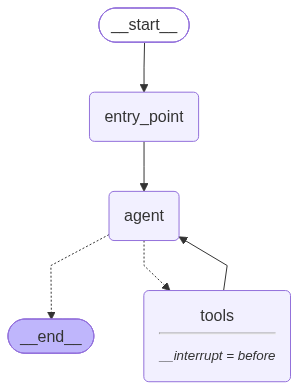

In [11]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [12]:
thread_id_1 = str(uuid4()) 

In [13]:
input_question = {"question": "what's the capital of Brazil?"}
config = {"configurable": {"thread_id": thread_id_1}}

In [14]:
for chunk in graph.stream(input=input_question, config=config, stream_mode="values"):
    if not chunk["messages"]:
        continue
    chunk["messages"][-1].pretty_print()

================================ Human Message =================================

what's the capital of Brazil?
================================== Ai Message ==================================

[{'arguments': '{"question":"What is the capital of Brazil?"}', 'call_id': 'call_66f20e6c83604cb7adae51d1cc8dc2ea', 'name': 'web_search', 'type': 'function_call', 'id': 'fc_0cf698ddfe3167dc006b029e5635ec87d0b8e0befe8600f96e', 'status': 'completed'}]
Tool Calls:
  web_search (call_66f20e6c83604cb7adae51d1cc8dc2ea)
 Call ID: call_66f20e6c83604cb7adae51d1cc8dc2ea
  Args:
    question: What is the capital of Brazil?


In [15]:
state = graph.get_state(config=config)

In [16]:
state

StateSnapshot(values={'messages': [SystemMessage(content="You conduct web search to respond to user's questions using the available tools only.", additional_kwargs={}, response_metadata={}, id='8781e800-8ec5-42d4-9806-2821e7199987'), HumanMessage(content="what's the capital of Brazil?", additional_kwargs={}, response_metadata={}, id='25746caf-5e5f-4be1-a519-1059d6ac601d'), AIMessage(content=[{'arguments': '{"question":"What is the capital of Brazil?"}', 'call_id': 'call_66f20e6c83604cb7adae51d1cc8dc2ea', 'name': 'web_search', 'type': 'function_call', 'id': 'fc_0cf698ddfe3167dc006b029e5635ec87d0b8e0befe8600f96e', 'status': 'completed'}], additional_kwargs={}, response_metadata={'id': 'resp_0cf698ddfe3167dc006b029e55550087d0ac696fbbf24f61bf', 'created_at': 1795333717.0, 'metadata': {}, 'model': 'gpt-5.6-sol', 'object': 'response', 'service_tier': 'default', 'status': 'completed', 'model_provider': 'openai', 'model_name': 'gpt-5.6-sol'}, id='resp_0cf698ddfe3167dc006b029e55550087d0ac696fbb

In [17]:
state.next

('tools',)

In [18]:
for chunk in graph.stream(input=None, config=config, stream_mode="values"):
    if not chunk["messages"]:
        continue
    chunk["messages"][-1].pretty_print()

================================== Ai Message ==================================

[{'arguments': '{"question":"What is the capital of Brazil?"}', 'call_id': 'call_66f20e6c83604cb7adae51d1cc8dc2ea', 'name': 'web_search', 'type': 'function_call', 'id': 'fc_0cf698ddfe3167dc006b029e5635ec87d0b8e0befe8600f96e', 'status': 'completed'}]
Tool Calls:
  web_search (call_66f20e6c83604cb7adae51d1cc8dc2ea)
 Call ID: call_66f20e6c83604cb7adae51d1cc8dc2ea
  Args:
    question: What is the capital of Brazil?
================================= Tool Message =================================
Name: web_search

{"query": "What is the capital of Brazil?", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.britannica.com/place/Brasilia", "title": "Brasilia | Facts, History, Map, Pronunciation & Architecture | Britannica", "content": "Brasília, city, federal capital of Brazil. It is located in the Federal District (Distrito Federal) carved out of Goiás state on the cent

In [19]:
def human_in_the_loop_run(graph:CompiledStateGraph, question:str, thread_id:str):
    input_question = {"question": question}
    config = {"configurable": {"thread_id": thread_id}}
    for event in graph.stream(input=input_question, config=config, stream_mode="values"):
        if not event['messages']:
            continue
        event['messages'][-1].pretty_print()
    
    human_input = input("Do you approve the tool calling? (YES or NO): ")
    if human_input.lower() == "yes":
        for event in graph.stream(input=None, config=config, stream_mode="values"):
            if not event['messages']:
                continue
            event['messages'][-1].pretty_print()
    
    else:
        SystemMessage("Workflow aborted by a human").pretty_print()

In [20]:
human_in_the_loop_run(
    graph=graph,
    question="what's the capital of Brazil?",
    thread_id=str(uuid4()),
)

================================ Human Message =================================

what's the capital of Brazil?
================================== Ai Message ==================================

[{'id': 'rs_00e9303f5e04f973006b029e84451487d0b20687803465a963', 'summary': [], 'type': 'reasoning', 'content': [], 'encrypted_content': 'gAAAAABrAp6Eob9SIu8rrQa98d4MYHDOHVOcBCOjum3D7egkt83TA9iXfRxTSUQEkA0uP6Sz5zDZwBhgZIPAfC80P0a0wv410Rl8QuBkvq7vBclHv-7dVc3n6ydcACwyTRKnuYahUAC9oJm9OjJk55c1dv4JqYhUyO9tBK_KCH-NKxFscvDQPkwK--V9EPQ1s1KxkSvyCIf513aakzmIlkrfwVipiL6bBb7SFXiUaCpoZtRi95A5jJDXoh8a9iLLtFO2tQ-Hn2pD9j39r09cyz8munz5FWN1t2zASfhKMeAPZI6YCccEL7n8wsm5ZYGN9QmZEyet4QLlvieq2xgfg3H5HtCfCh-Xceuvwy-AGJNUwDsPZ30O-2jM6bcgpzvTiA_Pf07gmnj-kI-dkt2FmcHebOmDO7zdXUiApRl9oLlcuq0sCdwfZt5nFigjK35DnqPtqSfat8CvBOiYZtsCOSPqwCXv06jBj9Lux8q8jdN4Vo_dl4G3cVxZJv06e7LJz8azSBa3oq0SqkO9kU_JsF_cyqFTBuo63vA7l2BY_vJU9yjpXTf9jtvT8_4ofJubOEXZG5pBj2CTd5M9fo908aj8BxxGPuZyDY-Qrif7bnczpUGQUKbuGfvdVaANMma_G2JzyNZcjji-gyrz__raLFt3yDhC

In [21]:
human_in_the_loop_run(
    graph=graph,
    question="what's the capital of Mexico?",
    thread_id=str(uuid4()),
)

================================ Human Message =================================

what's the capital of Mexico?
================================== Ai Message ==================================

[{'arguments': '{"question":"What is the capital of Mexico?"}', 'call_id': 'call_49ae638c460d47ed87d07cc16d57b1a9', 'name': 'web_search', 'type': 'function_call', 'id': 'fc_0d68887130ef79c2006b029e911b9487d0b75a0eed9961e192', 'status': 'completed'}]
Tool Calls:
  web_search (call_49ae638c460d47ed87d07cc16d57b1a9)
 Call ID: call_49ae638c460d47ed87d07cc16d57b1a9
  Args:
    question: What is the capital of Mexico?
================================ System Message ================================

Workflow aborted by a human


In [22]:
checkpointer = InMemorySaver()

graph = workflow.compile(interrupt_before=["agent"], checkpointer=checkpointer)

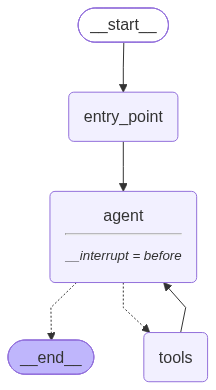

In [23]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [24]:
def human_in_the_loop_run(graph:CompiledStateGraph, question:str, thread_id:str):
    input_question = {"question": question}
    config = {"configurable": {"thread_id": thread_id}}
    for event in graph.stream(input=input_question, config=config, stream_mode="values"):
        if not event['messages']:
            continue
        event['messages'][-1].pretty_print()

    human_input = input("Do you want to proceed with this question? (YES or NO): ")
    
    if human_input.lower() == "no":
        human_input = input("So what should be the question? ")
        human_message = HumanMessage(content=human_input)
        system_message = SystemMessage("Workflow edited by a human")
        system_message.pretty_print()
        graph.update_state(
            config=config,
            values={
                "messages": [
                    system_message,
                    human_message,
                ]
            },
        )

        for event in graph.stream(input=None, config=config, stream_mode="values"):
            if not event['messages']:
                continue
            event['messages'][-1].pretty_print()
    
    for event in graph.stream(input=None, config=config, stream_mode="values"):
        if not event['messages']:
            continue
        event['messages'][-1].pretty_print()


In [25]:
human_in_the_loop_run(
    graph=graph,
    question="what's the capital of Brazil?",
    thread_id=str(uuid4()),
)

================================ Human Message =================================

what's the capital of Brazil?
================================ System Message ================================

Workflow edited by a human
================================ Human Message =================================

What is the capital of Australia?
================================== Ai Message ==================================

[{'arguments': '{"question":"What is the capital of Australia?"}', 'call_id': 'call_6522de91707e4e22934e0d3a4e429deb', 'name': 'web_search', 'type': 'function_call', 'id': 'fc_03d075452b268a4f006b029edd079487d08bd8fc098215f594', 'status': 'completed'}]
Tool Calls:
  web_search (call_6522de91707e4e22934e0d3a4e429deb)
 Call ID: call_6522de91707e4e22934e0d3a4e429deb
  Args:
    question: What is the capital of Australia?
================================= Tool Message =================================
Name: web_search

{"query": "What is the capital of Australia?", "follow_up_qu

In [26]:
human_in_the_loop_run(
    graph=graph,
    question="what's the capital of Brazil?",
    thread_id=str(uuid4()),
)

================================ Human Message =================================

what's the capital of Brazil?
================================ Human Message =================================

what's the capital of Brazil?
================================== Ai Message ==================================

[{'arguments': '{"question":"What is the capital of Brazil?"}', 'call_id': 'call_32f831fe92674974ac486dca3dac5bc7', 'name': 'web_search', 'type': 'function_call', 'id': 'fc_001ccb5c8d81df29006b029eecb94c87d081cc003befcb7462', 'status': 'completed'}]
Tool Calls:
  web_search (call_32f831fe92674974ac486dca3dac5bc7)
 Call ID: call_32f831fe92674974ac486dca3dac5bc7
  Args:
    question: What is the capital of Brazil?
================================= Tool Message =================================
Name: web_search

{"query": "What is the capital of Brazil?", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.britannica.com/place/Brasilia", "title": "B